# SIH-SUS - mortalidade intra-hospitalar e tempo de permanência

Este notebook constrói duas tarefas preditivas a partir dos arquivos **RD (Resumo de Internação)**:

1. **Classificação:** estimar o risco de mortalidade intra-hospitalar (`MORTE`).
2. **Regressão:** estimar o tempo total de permanência em dias (`DIAS_PERM`).

A unidade é a **AIH**, isto é, um evento de internação. As duas tarefas usam a mesma base e as mesmas features, mas possuem alvos, modelos, hiperparâmetros e métricas próprios.

## Protocolo

- admissões entre janeiro de 2024 e dezembro de 2025;
- arquivos até março de 2026 usados para capturar encerramentos de internações iniciadas em 2025;
- leitura incremental e amostra determinística para controlar memória;
- dez folds temporais externos, cada um testando um mês futuro;
- validação interna para hiperparâmetros, peso da classe positiva, calibração e limiar;
- previsões *out-of-fold* (OOF);
- uma seed fixa para garantir reprodutibilidade;
- mesmas linhas, features, alvos e folds na futura comparação clássica-quântica.


## 1. Importações


In [1]:
from pathlib import Path
import gc
import hashlib
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import LinearSVC, LinearSVR
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Configuração e controle de memória

A unidade de modelagem é a AIH. Para controlar o uso de memória sem restringir a cobertura geográfica, é utilizada uma amostra determinística de 1% das internações das 27 UFs.

A seleção é baseada no hash do número da AIH e em uma seed fixa. Esse procedimento torna a amostra reprodutível e mantém juntas as reapresentações da mesma AIH antes da consolidação. O ajuste de hiperparâmetros pode utilizar até 50 mil linhas do treino interno.


In [2]:
# Caminhos
DIR_SIH = Path.cwd()
if not (DIR_SIH / "dados" / "internacoes").exists():
    DIR_SIH = Path.cwd() / "SIH-SUS"

DIR_DADOS = DIR_SIH / "dados" / "internacoes"
DIR_SAIDA = DIR_SIH / "resultados_mortalidade_permanencia"

# Período e amostragem
DATA_INICIAL = pd.Timestamp("2024-01-01")
DATA_FINAL = pd.Timestamp("2025-12-31")
FRACAO_AMOSTRA = 0.01
SEED_AMOSTRA = 42

# Validação
N_SPLITS = 10
MESES_VALIDACAO_INTERNA = 2
SEED_TUNING = 42
MAX_LINHAS_TUNING = 50_000
MIN_FREQUENCIA_CATEGORIA = 30

# Uso de recursos
N_JOBS = 2
EXPORTAR_PROTOCOLO = True

print("Pasta dos dados:", DIR_DADOS.resolve())
print("Pasta encontrada:", DIR_DADOS.exists())

Pasta dos dados: /content/SIH-SUS/dados/internacoes
Pasta encontrada: False


## 3. Colunas e features

As duas tarefas usam a mesma matriz de entrada. Os históricos do estabelecimento podem contribuir para ambos os problemas:

- mortalidade histórica representa o risco e a complexidade assistencial do hospital;
- permanência histórica representa o perfil de utilização de leitos;
- volume histórico representa o porte e a experiência do estabelecimento.

As demais informações são conhecidas ou assumidas como disponíveis na autorização/início da internação: idade, sexo, raça/cor, caráter, especialidade, complexidade, financiamento, gestão, diagnóstico principal e procedimento solicitado.

O CID usa capítulo e categoria de três caracteres. O procedimento usa grupo e subgrupo de quatro dígitos. Categorias raras são agrupadas durante o pré-processamento.

Não entram variáveis posteriores ao desfecho, como `DT_SAIDA`, `COBRANCA`, `PROC_REA`, custos, diárias e uso de UTI. A data de saída é usada apenas para confirmar encerramento e consolidar reapresentações.


In [3]:
COLUNAS_BRUTAS = [
    "N_AIH", "CNES", "DT_INTER", "DT_SAIDA", "MUNIC_RES", "MUNIC_MOV",
    "COD_IDADE", "IDADE", "SEXO", "RACA_COR", "CAR_INT", "ESPEC",
    "COMPLEX", "FINANC", "GESTAO", "DIAG_PRINC", "PROC_SOLIC",
    "DIAS_PERM", "MORTE",
]

FEATURES_NUM = [
    "idade_anos",
    "entrada_fim_semana",
    "historico_mortalidade_cnes",
    "historico_permanencia_cnes",
    "historico_volume_cnes",
]
FEATURES_CAT = [
    "sexo", "raca_cor", "car_int", "especialidade", "complexidade",
    "financiamento", "gestao", "cid_capitulo", "cid_categoria",
    "procedimento_grupo", "procedimento_subgrupo", "uf_atendimento",
    "uf_residencia", "mes_internacao",
]
FEATURES = FEATURES_NUM + FEATURES_CAT

ALVO_REG = "dias_permanencia"
ALVO_CLF = "morte"

display(pd.DataFrame({
    "tipo": ["Numérica"] * len(FEATURES_NUM) + ["Categórica"] * len(FEATURES_CAT),
    "feature": FEATURES,
}))
print("Alvos:", ALVO_REG, "e", ALVO_CLF)


,tipo,feature
0,Numérica,idade_anos
1,Numérica,entrada_fim_semana
2,Numérica,historico_mortalidade_cnes
3,Numérica,historico_permanencia_cnes
4,Numérica,historico_volume_cnes
5,Categórica,sexo
6,Categórica,raca_cor
7,Categórica,car_int
8,Categórica,especialidade
9,Categórica,complexidade


Alvos: dias_permanencia e morte


## 4. Leitura incremental e amostragem

Cada Parquet é aberto separadamente e somente as 19 colunas necessárias são lidas. Antes da concatenação, ficam apenas as AIHs selecionadas pelo hash determinístico. Essa ordem evita *out of memory*.

Arquivos até março de 2026 são lidos somente para capturar o encerramento de internações iniciadas em 2025. A coorte final continua limitada a admissões de 2024-2025.


In [4]:
def metadados_arquivo(caminho):
    busca = re.fullmatch(r"RD_([A-Z]{2})_(\d{6})", caminho.stem)
    if not busca:
        return None
    return {"uf_arquivo": busca.group(1), "competencia": busca.group(2)}


def converter_data(serie):
    texto = serie.astype("string").str.strip().replace({"": pd.NA, "00000000": pd.NA})
    return pd.to_datetime(texto, format="%Y%m%d", errors="coerce")


def selecionar_por_hash(ids, fracao):
    if not 0 < fracao <= 1:
        raise ValueError("FRACAO_AMOSTRA deve estar entre 0 e 1.")
    if fracao == 1:
        return np.ones(len(ids), dtype=bool)
    chaves = ids.astype("string") + f"-{SEED_AMOSTRA}"
    hashes = pd.util.hash_pandas_object(chaves, index=False).to_numpy()
    limite = np.uint64(int(fracao * (2**64 - 1)))
    return hashes <= limite


arquivos = []
for caminho in sorted(DIR_DADOS.glob("RD_*.parquet")):
    meta = metadados_arquivo(caminho)
    if meta and "202401" <= meta["competencia"] <= "202603":
        arquivos.append((caminho, meta))

if not arquivos:
    raise FileNotFoundError(f"Nenhum arquivo RD de 2024–2025 em {DIR_DADOS.resolve()}")

inventario = pd.DataFrame([
    {**meta, "arquivo": caminho.name, "mb": caminho.stat().st_size / 1024**2}
    for caminho, meta in arquivos
])
print(f"Arquivos selecionados: {len(inventario)}")
display(inventario.groupby("uf_arquivo").agg(
    arquivos=("arquivo", "count"),
    primeira_competencia=("competencia", "min"),
    ultima_competencia=("competencia", "max"),
    tamanho_mb=("mb", "sum"),
).round(1))

FileNotFoundError: Nenhum arquivo RD de 2024–2025 em /content/SIH-SUS/dados/internacoes

In [5]:
partes = []
erros_leitura = []

for numero, (caminho, meta) in enumerate(arquivos, 1):
    try:
        parte = pd.read_parquet(caminho, columns=COLUNAS_BRUTAS)
        parte = parte.loc[selecionar_por_hash(parte["N_AIH"], FRACAO_AMOSTRA)].copy()
        parte["uf_arquivo"] = meta["uf_arquivo"]
        partes.append(parte)
    except Exception as erro:
        erros_leitura.append({"arquivo": caminho.name, "erro": str(erro)})

    if numero % 25 == 0 or numero == len(arquivos):
        print(f"Lidos {numero:>3}/{len(arquivos)} arquivos | partes mantidas: {len(partes)}")

if erros_leitura:
    display(pd.DataFrame(erros_leitura))
    raise RuntimeError("Houve erro na leitura. Corrija antes de continuar.")

base = pd.concat(partes, ignore_index=True)
del partes
gc.collect()

base["data_internacao"] = converter_data(base["DT_INTER"])
base["data_saida"] = converter_data(base["DT_SAIDA"])
base[ALVO_REG] = pd.to_numeric(base["DIAS_PERM"], errors="coerce")
base[ALVO_CLF] = pd.to_numeric(base["MORTE"], errors="coerce")

base = base.loc[
    base["data_internacao"].between(DATA_INICIAL, DATA_FINAL)
    & base["data_saida"].notna()
    & base["data_saida"].ge(base["data_internacao"])
    & base[ALVO_REG].between(0, 365)
    & base[ALVO_CLF].isin([0, 1])
].copy()

# Reapresentações da mesma AIH ficam juntas pela amostragem. Mantemos a versão
# com a data de saída mais recente, que representa o encerramento conhecido
n_antes = len(base)
base = (
    base.sort_values(["N_AIH", "data_saida"], na_position="first")
    .drop_duplicates("N_AIH", keep="last")
    .reset_index(drop=True)
)

dias_pelas_datas = (base["data_saida"] - base["data_internacao"]).dt.days
divergencia_dias = (dias_pelas_datas - base[ALVO_REG]).abs()

print(f"Linhas após filtros: {len(base):,}")
print(f"Duplicatas removidas: {n_antes - len(base):,}")
print(f"AIHs únicas: {base['N_AIH'].nunique():,}")
print(f"DIAS_PERM divergente das datas em mais de 1 dia: {(divergencia_dias > 1).mean():.2%}")

ValueError: No objects to concatenate

## 5. Engenharia de features

No SIH, `COD_IDADE` informa a unidade de `IDADE`: 2 para dias, 3 para meses e 4 para anos.

Os históricos do estabelecimento são construídos mês a mês usando apenas internações de meses anteriores. Assim, a mortalidade ou a permanência do mês previsto nunca entra em suas próprias features.

O identificador CNES não entra diretamente no modelo. Ele serve apenas para calcular os históricos, reduzindo memorização do estabelecimento e permitindo tratar hospitais novos como valores ausentes.


In [ ]:
def idade_em_anos(codigo, valor):
    codigo = pd.to_numeric(codigo, errors="coerce")
    valor = pd.to_numeric(valor, errors="coerce")
    idade = pd.Series(np.nan, index=valor.index, dtype="float64")
    idade.loc[codigo.eq(2)] = valor.loc[codigo.eq(2)] / 365.25
    idade.loc[codigo.eq(3)] = valor.loc[codigo.eq(3)] / 12
    idade.loc[codigo.eq(4)] = valor.loc[codigo.eq(4)]
    return idade.where(idade.between(0, 110))


base["idade_anos"] = idade_em_anos(base["COD_IDADE"], base["IDADE"])
base["entrada_fim_semana"] = base["data_internacao"].dt.dayofweek.ge(5).astype("int8")
base["mes_internacao"] = base["data_internacao"].dt.month.astype("string")
base["mes"] = base["data_internacao"].dt.to_period("M").dt.to_timestamp()
base["cnes"] = base["CNES"].astype("string").str.strip().replace("", pd.NA)

cid = base["DIAG_PRINC"].astype("string").str.strip().str.upper()
base["cid_capitulo"] = cid.str[:1].where(cid.str.match(r"[A-Z]", na=False), "NI")
base["cid_categoria"] = cid.str[:3].where(cid.str.match(r"[A-Z][0-9]{2}", na=False), "NI")

procedimento = base["PROC_SOLIC"].astype("string").str.strip()
base["procedimento_grupo"] = procedimento.str[:2].where(
    procedimento.str.match(r"\d{2}", na=False), "NI"
)
base["procedimento_subgrupo"] = procedimento.str[:4].where(
    procedimento.str.match(r"\d{4}", na=False), "NI"
)
base["uf_atendimento"] = base["uf_arquivo"].astype("string")
base["uf_residencia"] = base["MUNIC_RES"].astype("string").str.zfill(6).str[:2]

renomear = {
    "SEXO": "sexo", "RACA_COR": "raca_cor", "CAR_INT": "car_int",
    "ESPEC": "especialidade", "COMPLEX": "complexidade",
    "FINANC": "financiamento", "GESTAO": "gestao",
}
base = base.rename(columns=renomear)
for coluna in FEATURES_CAT:
    valores = base[coluna].astype("string").str.strip().replace("", pd.NA)
    base[coluna] = valores.where(valores.notna(), np.nan).astype(object)

# Estatísticas históricas por CNES-mês. O mês atual é subtraído do acumulado.
historico = base.groupby(["cnes", "mes"], dropna=False, as_index=False).agg(
    internacoes_mes=("N_AIH", "size"),
    obitos_mes=(ALVO_CLF, "sum"),
    dias_mes=(ALVO_REG, "sum"),
)
historico = historico.sort_values(["cnes", "mes"])
grupo_cnes = historico.groupby("cnes", dropna=False, sort=False)
historico["meses_anteriores"] = grupo_cnes.cumcount()
historico["internacoes_anteriores"] = (
    grupo_cnes["internacoes_mes"].cumsum() - historico["internacoes_mes"]
)
historico["obitos_anteriores"] = grupo_cnes["obitos_mes"].cumsum() - historico["obitos_mes"]
historico["dias_anteriores"] = grupo_cnes["dias_mes"].cumsum() - historico["dias_mes"]

divisor = historico["internacoes_anteriores"].replace(0, np.nan)
historico["historico_mortalidade_cnes"] = historico["obitos_anteriores"] / divisor
historico["historico_permanencia_cnes"] = historico["dias_anteriores"] / divisor
historico["historico_volume_cnes"] = (
    historico["internacoes_anteriores"]
    / historico["meses_anteriores"].replace(0, np.nan)
)

base = base.merge(
    historico[[
        "cnes", "mes", "historico_mortalidade_cnes",
        "historico_permanencia_cnes", "historico_volume_cnes",
    ]],
    on=["cnes", "mes"], how="left", validate="many_to_one",
)
colunas_historicas = [
    "historico_mortalidade_cnes", "historico_permanencia_cnes",
    "historico_volume_cnes",
]
base.loc[base["cnes"].isna(), colunas_historicas] = np.nan

base[ALVO_CLF] = base[ALVO_CLF].astype("int8")
base[ALVO_REG] = base[ALVO_REG].astype("float32")
base["id_linha"] = np.arange(len(base), dtype=np.int64)

base_modelagem = base[[
    "id_linha", "N_AIH", "data_internacao", "mes", *FEATURES,
    ALVO_REG, ALVO_CLF,
]].sort_values(["mes", "id_linha"]).reset_index(drop=True)

del base, historico
gc.collect()
print("Dimensão da base de modelagem:", base_modelagem.shape)
display(base_modelagem.head())


Dimensão da base de modelagem: (285779, 25)


,id_linha,N_AIH,data_internacao,mes,idade_anos,entrada_fim_semana,historico_mortalidade_cnes,historico_permanencia_cnes,historico_volume_cnes,sexo,raca_cor,car_int,especialidade,complexidade,financiamento,gestao,cid_capitulo,cid_categoria,procedimento_grupo,procedimento_subgrupo,uf_atendimento,uf_residencia,mes_internacao,dias_permanencia,morte
0,0,1123100392469,2024-01-22,2024-01-01,62.0000,0,NaN,NaN,NaN,1,03,02,03,03,04,2,Z,Z52,05,0503,RO,11,1,0.0000,0
1,1,1123100907930,2024-01-08,2024-01-01,45.0000,0,NaN,NaN,NaN,1,03,02,03,02,06,1,J,J18,03,0303,RO,11,1,3.0000,1
2,2,1123100909271,2024-01-12,2024-01-01,70.0000,0,NaN,NaN,NaN,3,01,02,01,02,06,1,S,S96,04,0408,RO,11,1,6.0000,0
3,3,1123100909326,2024-01-11,2024-01-01,4.0000,0,NaN,NaN,NaN,3,01,02,01,02,06,1,S,S68,04,0408,RO,11,1,1.0000,0
4,4,1123100912571,2024-01-06,2024-01-01,21.0000,1,NaN,NaN,NaN,3,03,02,05,02,06,1,F,F41,03,0303,RO,11,1,12.0000,0


## 6. Verificações de qualidade

Esta seção verifica período, duplicidade, nulos, cardinalidade, distribuição dos alvos e maturidade temporal.

Não usei SMOTE. O peso dos óbitos passa a ser um hiperparâmetro escolhido somente na validação interna. Valores numéricos ausentes são preenchidos pela mediana do treino; categóricos ausentes, pela moda do treino. Categorias novas ou raras são tratadas pelo codificador dentro de cada fold.


In [ ]:
assert base_modelagem["N_AIH"].is_unique, "Ainda existem AIHs duplicadas."
assert base_modelagem["data_internacao"].between(DATA_INICIAL, DATA_FINAL).all()
assert base_modelagem[ALVO_REG].between(0, 365).all()
assert set(base_modelagem[ALVO_CLF].unique()).issubset({0, 1})

qualidade = pd.DataFrame({
    "dtype": base_modelagem.dtypes.astype(str),
    "nulos": base_modelagem.isna().sum(),
    "nulos_pct": base_modelagem.isna().mean().mul(100),
    "valores_unicos": base_modelagem.nunique(dropna=True),
}).sort_values("nulos_pct", ascending=False)

print("Período:", base_modelagem["data_internacao"].min().date(), "a", base_modelagem["data_internacao"].max().date())
print(f"Mortalidade: {base_modelagem[ALVO_CLF].mean():.2%} ({base_modelagem[ALVO_CLF].sum():,} óbitos)")
print("Tempo de permanência:")
display(base_modelagem[ALVO_REG].describe(percentiles=[.5, .75, .9, .95, .99]).to_frame().T)
print("Qualidade das features e alvos:")
display(qualidade.loc[FEATURES + [ALVO_REG, ALVO_CLF]])

print("Cardinalidade clínica antes do agrupamento de categorias raras:")
display(qualidade.loc[["cid_capitulo", "cid_categoria", "procedimento_grupo", "procedimento_subgrupo"], ["valores_unicos", "nulos_pct"]])


Período: 2024-01-01 a 2025-12-31
Mortalidade: 4.42% (12,639 óbitos)
Tempo de permanência:


,count,mean,std,min,50%,75%,90%,95%,99%,max
dias_permanencia,"285,779.0000",4.7592,6.9398,0.0000,2.0000,5.0000,11.0000,18.0000,32.0000,336.0000


Qualidade das features e alvos:


,dtype,nulos,nulos_pct,valores_unicos
idade_anos,float64,206,0.0721,141
entrada_fim_semana,int8,0,0.0000,2
historico_mortalidade_cnes,float64,13768,4.8177,2821
historico_permanencia_cnes,float64,13768,4.8177,17340
historico_volume_cnes,float64,13768,4.8177,3121
sexo,object,0,0.0000,2
raca_cor,object,0,0.0000,5
car_int,object,0,0.0000,6
especialidade,object,0,0.0000,14
complexidade,object,0,0.0000,2


Cardinalidade clínica antes do agrupamento de categorias raras:


,valores_unicos,nulos_pct
cid_capitulo,22,0.0000
cid_categoria,1483,0.0000
procedimento_grupo,4,0.0000
procedimento_subgrupo,30,0.0000


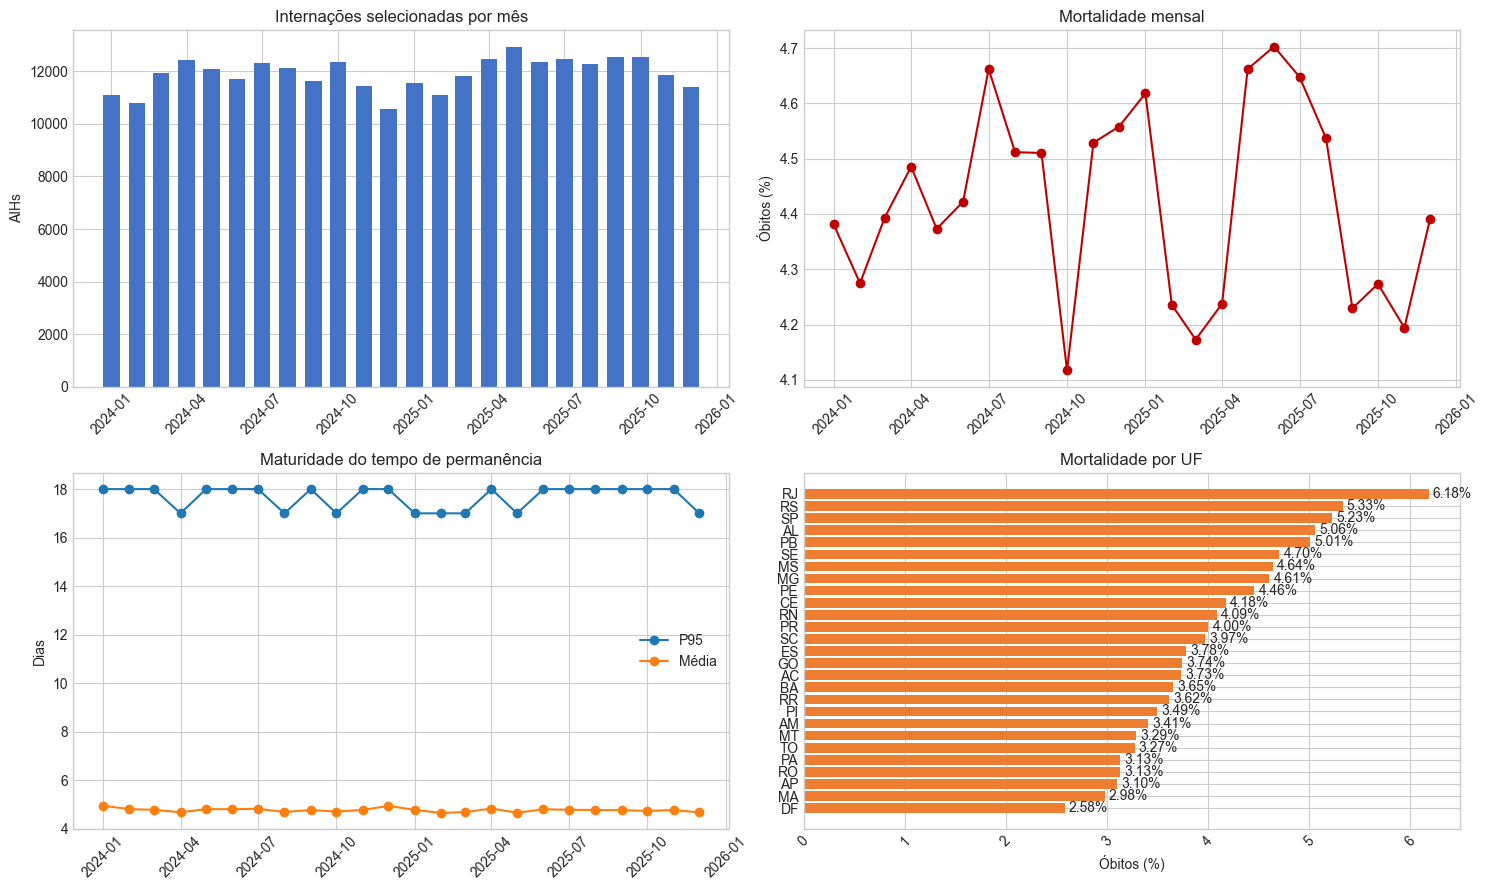

Verificação mensal de maturidade


,mes,internacoes,obitos,mortalidade,permanencia_mediana,permanencia_media,permanencia_p95,permanencia_maxima,pct_mais_30_dias
0,2024-01-01,11092,486,0.0438,2.0000,4.9422,18.0000,336.0000,0.0152
1,2024-02-01,10784,461,0.0427,2.0000,4.7994,18.0000,184.0000,0.0109
2,2024-03-01,11927,524,0.0439,2.0000,4.7729,18.0000,247.0000,0.0117
3,2024-04-01,12418,557,0.0449,2.0000,4.6704,17.0000,96.0000,0.0100
4,2024-05-01,12074,528,0.0437,3.0000,4.8001,18.0000,120.0000,0.0114
5,2024-06-01,11691,517,0.0442,2.0000,4.7982,18.0000,95.0000,0.0127
6,2024-07-01,12312,574,0.0466,2.0000,4.8138,18.0000,186.0000,0.0129
7,2024-08-01,12124,547,0.0451,2.0000,4.6839,17.0000,101.0000,0.0116
8,2024-09-01,11640,525,0.0451,2.0000,4.7613,18.0000,97.0000,0.0138
9,2024-10-01,12363,509,0.0412,2.0000,4.7026,17.0000,162.0000,0.0128


In [ ]:
mensal = base_modelagem.groupby("mes", as_index=False).agg(
    internacoes=("id_linha", "size"),
    obitos=(ALVO_CLF, "sum"),
    mortalidade=(ALVO_CLF, "mean"),
    permanencia_mediana=(ALVO_REG, "median"),
    permanencia_media=(ALVO_REG, "mean"),
    permanencia_p95=(ALVO_REG, lambda s: s.quantile(.95)),
    permanencia_maxima=(ALVO_REG, "max"),
    pct_mais_30_dias=(ALVO_REG, lambda s: s.gt(30).mean()),
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].bar(mensal["mes"], mensal["internacoes"], width=20, color="#4472C4")
axes[0, 0].set_title("Internações selecionadas por mês"); axes[0, 0].set_ylabel("AIHs")

axes[0, 1].plot(mensal["mes"], mensal["mortalidade"] * 100, marker="o", color="#C00000")
axes[0, 1].set_title("Mortalidade mensal"); axes[0, 1].set_ylabel("Óbitos (%)")

axes[1, 0].plot(mensal["mes"], mensal["permanencia_p95"], marker="o", label="P95")
axes[1, 0].plot(mensal["mes"], mensal["permanencia_media"], marker="o", label="Média")
axes[1, 0].set_title("Maturidade do tempo de permanência"); axes[1, 0].set_ylabel("Dias"); axes[1, 0].legend()

taxa_uf = base_modelagem.groupby("uf_atendimento")[ALVO_CLF].agg(["mean", "size"]).sort_values("mean")
barras = axes[1, 1].barh(taxa_uf.index, taxa_uf["mean"] * 100, color="#ED7D31")
axes[1, 1].bar_label(barras, fmt="%.2f%%", padding=3)
axes[1, 1].set_title("Mortalidade por UF"); axes[1, 1].set_xlabel("Óbitos (%)")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print("Verificação mensal de maturidade")
display(mensal)


## 7. Folds temporais

Não usei `KFold` aleatório porque ele permitiria treinar com internações futuras e testar em internações passadas. Os dez folds abaixo simulam uso real: o treino contém somente meses anteriores e o teste é o mês seguinte reservado para aquele fold.

Dentro de cada treino externo, os dois meses mais recentes formam a validação interna. Hiperparâmetros e limiar são escolhidos ali; o mês de teste não participa dessas escolhas.


In [ ]:
def criar_folds_temporais(df, n_splits):
    meses = np.array(sorted(df["mes"].unique()))
    if len(meses) < n_splits + MESES_VALIDACAO_INTERNA + 6:
        raise ValueError("Histórico insuficiente para os folds configurados.")

    meses_teste = meses[-n_splits:]
    folds = []
    for numero, mes_teste in enumerate(meses_teste, 1):
        idx_treino = np.flatnonzero(df["mes"].lt(mes_teste).to_numpy())
        idx_teste = np.flatnonzero(df["mes"].eq(mes_teste).to_numpy())
        folds.append((idx_treino, idx_teste))
        print(
            f"Fold {numero:02d} | treino: {df.iloc[idx_treino]['mes'].min().date()} a "
            f"{df.iloc[idx_treino]['mes'].max().date()} ({len(idx_treino):,}) | "
            f"teste: {pd.Timestamp(mes_teste).date()} ({len(idx_teste):,})"
        )
    return folds


def separar_validacao_interna(treino_externo):
    meses = np.array(sorted(treino_externo["mes"].unique()))
    inicio_validacao = meses[-MESES_VALIDACAO_INTERNA]
    treino = treino_externo.loc[treino_externo["mes"].lt(inicio_validacao)].copy()
    validacao = treino_externo.loc[treino_externo["mes"].ge(inicio_validacao)].copy()
    assert treino["mes"].max() < validacao["mes"].min()
    return treino, validacao


folds_externos = criar_folds_temporais(base_modelagem, N_SPLITS)


Fold 01 | treino: 2024-01-01 a 2025-02-01 (163,098) | teste: 2025-03-01 (11,838)
Fold 02 | treino: 2024-01-01 a 2025-03-01 (174,936) | teste: 2025-04-01 (12,483)
Fold 03 | treino: 2024-01-01 a 2025-04-01 (187,419) | teste: 2025-05-01 (12,913)
Fold 04 | treino: 2024-01-01 a 2025-05-01 (200,332) | teste: 2025-06-01 (12,355)
Fold 05 | treino: 2024-01-01 a 2025-06-01 (212,687) | teste: 2025-07-01 (12,458)
Fold 06 | treino: 2024-01-01 a 2025-07-01 (225,145) | teste: 2025-08-01 (12,299)
Fold 07 | treino: 2024-01-01 a 2025-08-01 (237,444) | teste: 2025-09-01 (12,531)
Fold 08 | treino: 2024-01-01 a 2025-09-01 (249,975) | teste: 2025-10-01 (12,542)
Fold 09 | treino: 2024-01-01 a 2025-10-01 (262,517) | teste: 2025-11-01 (11,873)
Fold 10 | treino: 2024-01-01 a 2025-11-01 (274,390) | teste: 2025-12-01 (11,389)


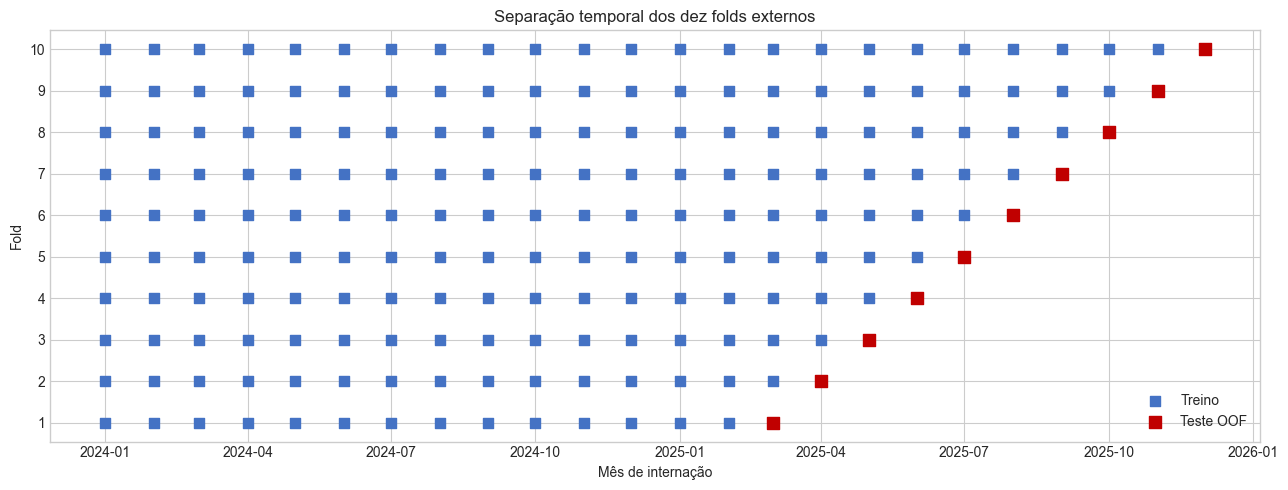

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
for fold, (idx_tr, idx_te) in enumerate(folds_externos, 1):
    meses_tr = base_modelagem.iloc[idx_tr]["mes"].drop_duplicates()
    meses_te = base_modelagem.iloc[idx_te]["mes"].drop_duplicates()
    ax.scatter(meses_tr, [fold] * len(meses_tr), marker="s", s=55, color="#4472C4",
               label="Treino" if fold == 1 else None)
    ax.scatter(meses_te, [fold] * len(meses_te), marker="s", s=70, color="#C00000",
               label="Teste OOF" if fold == 1 else None)
ax.set_yticks(range(1, N_SPLITS + 1))
ax.set_ylabel("Fold")
ax.set_xlabel("Mês de internação")
ax.set_title("Separação temporal dos dez folds externos")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Métricas

**Regressão:** MAE permanece principal e informa o erro médio em dias. RMSE enfatiza erros em permanências longas, erro mediano mostra o caso típico e R² mede a variação explicada. Também reportamos erro do total mensal de diárias e desempenho por faixa de permanência.

**Classificação:** Average Precision permanece principal por causa da baixa prevalência de óbito. Também reportamos precisão, recall, F1, balanced accuracy, ROC AUC e Brier score. O Brier score e a curva de calibração verificam se o risco previsto se aproxima da frequência observada.

As referências ingênuas são a mediana do treino e a prevalência do treino. Persistência não se aplica a novas internações.


In [ ]:
def metricas_regressao(y_true, y_pred):
    pred = np.clip(np.asarray(y_pred), 0, None)
    return {
        "mae": mean_absolute_error(y_true, pred),
        "rmse": mean_squared_error(y_true, pred) ** 0.5,
        "erro_mediano": median_absolute_error(y_true, pred),
        "r2": r2_score(y_true, pred),
    }

def metricas_classificacao(y_true, score, pred):
    duas_classes = np.unique(y_true).size == 2
    score = np.clip(np.asarray(score), 0, 1)
    return {
        "average_precision": average_precision_score(y_true, score) if duas_classes else np.nan,
        "roc_auc": roc_auc_score(y_true, score) if duas_classes else np.nan,
        "brier": brier_score_loss(y_true, score),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
    }

def escolher_limiar(y_true, score):
    precisao, recall, limiares = precision_recall_curve(y_true, score)
    if len(limiares) == 0:
        return 0.5
    f1 = 2 * precisao[:-1] * recall[:-1] / (precisao[:-1] + recall[:-1] + 1e-12)
    return float(limiares[int(np.nanargmax(f1))])

def score_classificador(pipeline, X):
    if hasattr(pipeline, "predict_proba"):
        return pipeline.predict_proba(X)[:, 1]
    return np.asarray(pipeline.decision_function(X))

def calibrar_scores(y_validacao, score_validacao, score_teste):
    calibrador = LogisticRegression(C=1_000, max_iter=2_000)
    calibrador.fit(np.asarray(score_validacao).reshape(-1, 1), y_validacao)
    prob_validacao = calibrador.predict_proba(np.asarray(score_validacao).reshape(-1, 1))[:, 1]
    prob_teste = calibrador.predict_proba(np.asarray(score_teste).reshape(-1, 1))[:, 1]
    return prob_validacao, prob_teste

## 9. Modelos e hiperparâmetros

As grades de hiperparâmetros foram definidas para comparar configurações representativas com custo computacional controlado.

Para regressão, HistGradientBoosting usa perda quantílica e XGBoost usa erro absoluto, alinhando o treinamento ao MAE. Para mortalidade, o peso positivo (`1`, `10` ou balanceamento completo) também é escolhido na validação interna.

Todos recebem as mesmas features. Modelos lineares, Random Forest e XGBoost usam *one-hot* esparso. HistGradientBoosting usa codificação ordinal porque não aceita a matriz esparsa. Essa diferença é necessária para controlar memória, mas não altera as informações oferecidas aos modelos.


In [ ]:
MODELOS_REGRESSAO = ["poisson", "linear_svm", "hist_gradient_boosting", "random_forest", "xgboost"]
MODELOS_CLASSIFICACAO = ["regressao_logistica", "linear_svm", "hist_gradient_boosting", "random_forest", "xgboost"]

NOMES_MODELOS = {
    "poisson": "Poisson", "regressao_logistica": "Regressão logística",
    "linear_svm": "SVM linear", "hist_gradient_boosting": "HistGradientBoosting",
    "random_forest": "Random Forest", "xgboost": "XGBoost",
    "mediana_treino": "Mediana do treino", "prevalencia_treino": "Prevalência do treino",
}

GRADES_REGRESSAO = {
    "poisson": {"alpha": [0.001, 0.01, 0.1, 1.0]},
    "linear_svm": {"C": [0.1, 1.0, 10.0], "epsilon": [0.0, 0.5]},
    "hist_gradient_boosting": {
        "learning_rate": [0.05, 0.10], "max_leaf_nodes": [31, 63],
        "min_samples_leaf": [20, 50], "l2_regularization": [1.0],
    },
    "random_forest": {
        "max_depth": [12, None], "min_samples_leaf": [5, 15],
        "max_features": ["sqrt", 0.3],
    },
    "xgboost": {
        "learning_rate": [0.05, 0.10], "max_depth": [4, 6, 8],
        "min_child_weight": [5, 10],
    },
}

PESOS_POSITIVOS = [1, 10, "balanced"]
GRADES_CLASSIFICACAO = {
    "regressao_logistica": {"C": [0.01, 0.1, 1.0], "peso_positivo": PESOS_POSITIVOS},
    "linear_svm": {"C": [0.1, 1.0, 10.0], "peso_positivo": PESOS_POSITIVOS},
    "hist_gradient_boosting": {
        "learning_rate": [0.05, 0.10], "max_leaf_nodes": [15, 31],
        "min_samples_leaf": [30], "l2_regularization": [1.0],
        "peso_positivo": PESOS_POSITIVOS,
    },
    "random_forest": {
        "max_depth": [12, None], "min_samples_leaf": [5, 15],
        "max_features": ["sqrt"], "peso_positivo": PESOS_POSITIVOS,
    },
    "xgboost": {
        "learning_rate": [0.05, 0.10], "max_depth": [4, 6],
        "min_child_weight": [5], "peso_positivo": PESOS_POSITIVOS,
    },
}

for tarefa, grades in [("Regressão", GRADES_REGRESSAO), ("Classificação", GRADES_CLASSIFICACAO)]:
    print(tarefa)
    for nome, grade in grades.items():
        print(f"  {NOMES_MODELOS[nome]:<25} {len(list(ParameterGrid(grade))):>2} combinações")

Regressão
  Poisson                    4 combinações
  SVM linear                 6 combinações
  HistGradientBoosting       8 combinações
  Random Forest              8 combinações
  XGBoost                   12 combinações
Classificação
  Regressão logística        9 combinações
  SVM linear                 9 combinações
  HistGradientBoosting      12 combinações
  Random Forest             12 combinações
  XGBoost                   12 combinações


In [ ]:
def criar_preprocessador(nome_modelo):
    numerico = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
    ])

    if nome_modelo == "hist_gradient_boosting":
        categorico = Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        sparse_threshold = 0.0
    else:
        categorico = Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("one_hot", OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=MIN_FREQUENCIA_CATEGORIA,
                sparse_output=True,
                dtype=np.float32,
            )),
        ])
        sparse_threshold = 1.0

    return ColumnTransformer([
        ("num", numerico, FEATURES_NUM),
        ("cat", categorico, FEATURES_CAT),
    ], remainder="drop", sparse_threshold=sparse_threshold)

def criar_regressor(nome, parametros, seed):
    if nome == "poisson":
        return PoissonRegressor(max_iter=5_000, tol=1e-4, **parametros)
    if nome == "linear_svm":
        return LinearSVR(dual="auto", max_iter=20_000, tol=1e-4, random_state=seed, **parametros)
    if nome == "hist_gradient_boosting":
        return HistGradientBoostingRegressor(
            loss="quantile", quantile=0.5, max_iter=250,
            early_stopping=False, random_state=seed, **parametros,
        )
    if nome == "random_forest":
        return RandomForestRegressor(n_estimators=120, n_jobs=N_JOBS, random_state=seed, **parametros)
    if nome == "xgboost":
        return XGBRegressor(
            objective="reg:absoluteerror", n_estimators=220,
            subsample=0.85, colsample_bytree=0.85, tree_method="hist",
            n_jobs=N_JOBS, random_state=seed, verbosity=0, **parametros,
        )
    raise KeyError(nome)

def criar_classificador(nome, parametros, seed):
    if nome == "regressao_logistica":
        return LogisticRegression(max_iter=2_000, random_state=seed, **parametros)
    if nome == "linear_svm":
        return LinearSVC(dual="auto", max_iter=10_000, random_state=seed, **parametros)
    if nome == "hist_gradient_boosting":
        return HistGradientBoostingClassifier(max_iter=250, early_stopping=False, random_state=seed, **parametros)
    if nome == "random_forest":
        return RandomForestClassifier(n_estimators=120, n_jobs=N_JOBS, random_state=seed, **parametros)
    if nome == "xgboost":
        return XGBClassifier(
            objective="binary:logistic", eval_metric="aucpr", n_estimators=220,
            subsample=0.85, colsample_bytree=0.85, tree_method="hist",
            n_jobs=N_JOBS, random_state=seed, verbosity=0, **parametros,
        )
    raise KeyError(nome)

def montar_pipeline(nome, modelo):
    return Pipeline([
        ("preprocessador", criar_preprocessador(nome)),
        ("modelo", modelo),
    ])

def limitar_amostra(df, limite, seed):
    return df if len(df) <= limite else df.sample(limite, random_state=seed).sort_index()

def separar_peso(parametros):
    parametros_modelo = dict(parametros)
    peso = parametros_modelo.pop("peso_positivo")
    return parametros_modelo, peso

## 10. Busca manual de hiperparâmetros

Regressão é selecionada pelo menor MAE e classificação pela maior Average Precision. Na classificação, a busca também seleciona o peso atribuído aos óbitos.

Somente para acelerar a busca, o treino interno pode ser limitado a 50 mil linhas. A validação interna normalmente é menor e permanece completa. Depois da escolha, o modelo é treinado novamente com todo o treino externo.


In [ ]:
def tuning_regressao(nome, grade, treino, validacao):
    treino_t = limitar_amostra(treino, MAX_LINHAS_TUNING, SEED_TUNING)
    validacao_t = limitar_amostra(validacao, MAX_LINHAS_TUNING, SEED_TUNING)
    linhas = []

    for parametros in ParameterGrid(grade):
        inicio = time.perf_counter()
        pipeline = None
        try:
            pipeline = montar_pipeline(nome, criar_regressor(nome, parametros, SEED_TUNING))
            pipeline.fit(treino_t[FEATURES], treino_t[ALVO_REG])
            pred = np.clip(pipeline.predict(validacao_t[FEATURES]), 0, None)
            valor, erro = mean_absolute_error(validacao_t[ALVO_REG], pred), None
        except Exception as exc:
            valor, erro = np.inf, str(exc)
        linhas.append({"parametros": parametros, "mae": valor,
                       "segundos": time.perf_counter() - inicio, "erro": erro})
        if pipeline is not None:
            del pipeline
        gc.collect()

    tabela = pd.DataFrame(linhas).sort_values("mae")
    if not np.isfinite(tabela.iloc[0]["mae"]):
        raise RuntimeError(f"Todas as configurações falharam para {nome}.")
    return dict(tabela.iloc[0]["parametros"]), tabela

def pesos_classificacao(y, peso_positivo):
    if peso_positivo == "balanced":
        return compute_sample_weight(class_weight="balanced", y=y)
    return np.where(np.asarray(y) == 1, float(peso_positivo), 1.0)

def ajustar_classificador(pipeline, treino, peso_positivo):
    pesos = pesos_classificacao(treino[ALVO_CLF], peso_positivo)
    pipeline.fit(treino[FEATURES], treino[ALVO_CLF], modelo__sample_weight=pesos)
    return pipeline

def tuning_classificacao(nome, grade, treino, validacao):
    treino_t = limitar_amostra(treino, MAX_LINHAS_TUNING, SEED_TUNING)
    validacao_t = limitar_amostra(validacao, MAX_LINHAS_TUNING, SEED_TUNING)
    linhas = []

    for parametros in ParameterGrid(grade):
        inicio = time.perf_counter()
        pipeline = None
        try:
            parametros_modelo, peso = separar_peso(parametros)
            pipeline = montar_pipeline(nome, criar_classificador(nome, parametros_modelo, SEED_TUNING))
            ajustar_classificador(pipeline, treino_t, peso)
            score = score_classificador(pipeline, validacao_t[FEATURES])
            valor, erro = average_precision_score(validacao_t[ALVO_CLF], score), None
        except Exception as exc:
            valor, erro = -np.inf, str(exc)
        linhas.append({"parametros": parametros, "average_precision": valor,
                       "segundos": time.perf_counter() - inicio, "erro": erro})
        if pipeline is not None:
            del pipeline
        gc.collect()

    tabela = pd.DataFrame(linhas).sort_values("average_precision", ascending=False)
    if not np.isfinite(tabela.iloc[0]["average_precision"]):
        raise RuntimeError(f"Todas as configurações falharam para {nome}.")
    return dict(tabela.iloc[0]["parametros"]), tabela

## 11. Regressão do tempo de permanência

Cada família escolhe seus hiperparâmetros na validação interna.

Cada modelo é treinado uma vez por fold com a seed fixa. Assim, há exatamente dez resultados por modelo, um para cada mês de teste.


In [ ]:
resultados_reg = []
selecoes_reg = []
previsoes_reg = []

for fold, (idx_tr, idx_te) in enumerate(folds_externos, 1):
    treino_externo = base_modelagem.iloc[idx_tr]
    teste_externo = base_modelagem.iloc[idx_te]
    treino_interno, validacao_interna = separar_validacao_interna(treino_externo)
    print(f"\nREGRESSÃO - fold {fold:02d}")

    # Referência ingênua calculada somente no treino.
    pred_base = np.repeat(treino_externo[ALVO_REG].median(), len(teste_externo))
    previsoes_reg.append(pd.DataFrame({
        "id_linha": teste_externo["id_linha"], "fold": fold,
        "modelo": "mediana_treino",
        "mes": teste_externo["mes"], "real": teste_externo[ALVO_REG], "previsto": pred_base,
    }))

    for nome in MODELOS_REGRESSAO:
        inicio_tuning = time.perf_counter()
        parametros, tabela = tuning_regressao(nome, GRADES_REGRESSAO[nome],
                                              treino_interno, validacao_interna)
        selecoes_reg.append({
            "fold": fold, "modelo": nome,
            "parametros": json.dumps(parametros, sort_keys=True),
            "mae_validacao_interna": tabela.iloc[0]["mae"],
            "tempo_tuning_s": time.perf_counter() - inicio_tuning,
        })

        inicio = time.perf_counter()
        pipeline = montar_pipeline(nome, criar_regressor(nome, parametros, SEED_TUNING))
        pipeline.fit(treino_externo[FEATURES], treino_externo[ALVO_REG])
        pred = np.clip(pipeline.predict(teste_externo[FEATURES]), 0, None)
        segundos = time.perf_counter() - inicio
        resultados_reg.append({
            "fold": fold, "modelo": nome, "segundos": segundos,
            **metricas_regressao(teste_externo[ALVO_REG], pred),
        })
        previsoes_reg.append(pd.DataFrame({
            "id_linha": teste_externo["id_linha"], "fold": fold,
            "modelo": nome, "mes": teste_externo["mes"],
            "real": teste_externo[ALVO_REG].to_numpy(), "previsto": pred,
        }))
        del pipeline
        gc.collect()
        print(NOMES_MODELOS[nome], "|", parametros)

resultados_reg = pd.DataFrame(resultados_reg)
selecoes_reg = pd.DataFrame(selecoes_reg)
previsoes_oof_reg = pd.concat(previsoes_reg, ignore_index=True)


REGRESSÃO - fold 01
Poisson | {'alpha': 0.001}
SVM linear | {'C': 1.0, 'epsilon': 0.5}
HistGradientBoosting | {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}
Random Forest | {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5}
XGBoost | {'learning_rate': 0.1, 'max_depth': 8, 'min_child_weight': 5}

REGRESSÃO - fold 02
Poisson | {'alpha': 0.001}
SVM linear | {'C': 1.0, 'epsilon': 0.5}
HistGradientBoosting | {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
Random Forest | {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5}
XGBoost | {'learning_rate': 0.1, 'max_depth': 8, 'min_child_weight': 10}

REGRESSÃO - fold 03
Poisson | {'alpha': 0.001}
SVM linear | {'C': 1.0, 'epsilon': 0.5}
HistGradientBoosting | {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
Random Forest | {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 

## 12. Classificação da mortalidade

O peso dos óbitos é escolhido junto com os hiperparâmetros. Isso permite comparar ausência de ponderação, peso intermediário e balanceamento completo sem consultar o teste.

Depois da escolha, um calibrador logístico é ajustado nos scores da validação interna. O limiar que maximiza F1 também é escolhido nessa validação. Probabilidade calibrada e limiar são então aplicados ao mês externo.

O notebook reporta o limiar, a taxa de alertas e a matriz de confusão. A regra de seleção do limiar deve ser mantida idêntica nas comparações entre modelos.


In [ ]:
resultados_clf = []
selecoes_clf = []
previsoes_clf = []

for fold, (idx_tr, idx_te) in enumerate(folds_externos, 1):
    treino_externo = base_modelagem.iloc[idx_tr]
    teste_externo = base_modelagem.iloc[idx_te]
    treino_interno, validacao_interna = separar_validacao_interna(treino_externo)
    print(f"\nCLASSIFICAÇÃO - fold {fold:02d}")

    score_base = np.repeat(treino_externo[ALVO_CLF].mean(), len(teste_externo))
    previsoes_clf.append(pd.DataFrame({
        "id_linha": teste_externo["id_linha"], "fold": fold,
        "modelo": "prevalencia_treino",
        "mes": teste_externo["mes"], "real": teste_externo[ALVO_CLF],
        "score": score_base, "previsto": np.zeros(len(teste_externo), dtype="int8"),
        "limiar": 0.5,
    }))

    for nome in MODELOS_CLASSIFICACAO:
        inicio_tuning = time.perf_counter()
        parametros, tabela = tuning_classificacao(
            nome, GRADES_CLASSIFICACAO[nome], treino_interno, validacao_interna
        )
        selecoes_clf.append({
            "fold": fold, "modelo": nome,
            "parametros": json.dumps(parametros, sort_keys=True),
            "ap_validacao_interna": tabela.iloc[0]["average_precision"],
            "tempo_tuning_s": time.perf_counter() - inicio_tuning,
        })

        parametros_modelo, peso = separar_peso(parametros)
        inicio = time.perf_counter()

        modelo_limiar = montar_pipeline(
            nome, criar_classificador(nome, parametros_modelo, SEED_TUNING)
        )
        ajustar_classificador(modelo_limiar, treino_interno, peso)
        score_interno_raw = score_classificador(modelo_limiar, validacao_interna[FEATURES])

        pipeline = montar_pipeline(
            nome, criar_classificador(nome, parametros_modelo, SEED_TUNING)
        )
        ajustar_classificador(pipeline, treino_externo, peso)
        score_teste_raw = score_classificador(pipeline, teste_externo[FEATURES])

        prob_interna, prob_teste = calibrar_scores(
            validacao_interna[ALVO_CLF], score_interno_raw, score_teste_raw
        )
        limiar = escolher_limiar(validacao_interna[ALVO_CLF], prob_interna)
        pred = (prob_teste >= limiar).astype("int8")
        segundos = time.perf_counter() - inicio

        resultados_clf.append({
            "fold": fold, "modelo": nome,
            "peso_positivo": peso, "limiar": limiar, "segundos": segundos,
            **metricas_classificacao(teste_externo[ALVO_CLF], prob_teste, pred),
        })
        previsoes_clf.append(pd.DataFrame({
            "id_linha": teste_externo["id_linha"], "fold": fold,
            "modelo": nome, "mes": teste_externo["mes"],
            "real": teste_externo[ALVO_CLF].to_numpy(), "score": prob_teste,
            "previsto": pred, "limiar": limiar,
        }))
        del modelo_limiar, pipeline
        gc.collect()
        print(NOMES_MODELOS[nome], "|", parametros)

resultados_clf = pd.DataFrame(resultados_clf)
selecoes_clf = pd.DataFrame(selecoes_clf)
previsoes_oof_clf = pd.concat(previsoes_clf, ignore_index=True)


CLASSIFICAÇÃO - fold 01
Regressão logística | {'C': 1.0, 'peso_positivo': 1}
SVM linear | {'C': 0.1, 'peso_positivo': 10}
HistGradientBoosting | {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'peso_positivo': 1}
Random Forest | {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'peso_positivo': 1}
XGBoost | {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 5, 'peso_positivo': 10}

CLASSIFICAÇÃO - fold 02
Regressão logística | {'C': 1.0, 'peso_positivo': 1}
SVM linear | {'C': 0.1, 'peso_positivo': 1}
HistGradientBoosting | {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'peso_positivo': 'balanced'}
Random Forest | {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'peso_positivo': 10}
XGBoost | {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 5, 'peso_positivo': 1}

CLASSIFICAÇÃO - fold 03
Regressão logística | {'C': 1.0, 'peso_positivo': 1}

## 13. Resultados por fold e limiares

A média entre os dez testes temporais é a comparação principal; o desvio mostra a variação entre meses.

Também são mostrados limiar, taxa de alertas e contagens da matriz de confusão.


In [ ]:
linhas_reg = []
for (modelo, fold), grupo in previsoes_oof_reg.groupby(["modelo", "fold"]):
    linhas_reg.append({"modelo": modelo, "fold": fold, "mes": grupo["mes"].iloc[0],
                       "linhas": len(grupo), **metricas_regressao(grupo["real"], grupo["previsto"])})
metricas_reg_fold = pd.DataFrame(linhas_reg)

linhas_clf = []
for (modelo, fold), grupo in previsoes_oof_clf.groupby(["modelo", "fold"]):
    tn, fp, fn, tp = confusion_matrix(grupo["real"], grupo["previsto"], labels=[0, 1]).ravel()
    linhas_clf.append({
        "modelo": modelo, "fold": fold, "mes": grupo["mes"].iloc[0], "linhas": len(grupo),
        "prevalencia": grupo["real"].mean(), "limiar": grupo["limiar"].mean(),
        "taxa_alertas": grupo["previsto"].mean(), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        **metricas_classificacao(grupo["real"], grupo["score"], grupo["previsto"]),
    })
metricas_clf_fold = pd.DataFrame(linhas_clf)

tempo_reg = resultados_reg[["modelo", "fold", "segundos"]]
tempo_clf = resultados_clf[["modelo", "fold", "segundos"]]
metricas_reg_fold = metricas_reg_fold.merge(tempo_reg, on=["modelo", "fold"], how="left")
metricas_clf_fold = metricas_clf_fold.merge(tempo_clf, on=["modelo", "fold"], how="left")

resumo_reg = metricas_reg_fold.groupby("modelo").agg(
    mae_media=("mae", "mean"), mae_desvio=("mae", "std"),
    rmse_media=("rmse", "mean"), rmse_desvio=("rmse", "std"),
    erro_mediano_media=("erro_mediano", "mean"), r2_media=("r2", "mean"),
    tempo_medio_s=("segundos", "mean"),
).sort_values("mae_media")

resumo_clf = metricas_clf_fold.groupby("modelo").agg(
    prevalencia_media=("prevalencia", "mean"),
    ap_media=("average_precision", "mean"), ap_desvio=("average_precision", "std"),
    brier_media=("brier", "mean"), precision_media=("precision", "mean"),
    recall_media=("recall", "mean"), f1_media=("f1", "mean"), f1_desvio=("f1", "std"),
    balanced_accuracy_media=("balanced_accuracy", "mean"), roc_auc_media=("roc_auc", "mean"),
    limiar_medio=("limiar", "mean"), limiar_desvio=("limiar", "std"),
    taxa_alertas_media=("taxa_alertas", "mean"), tempo_medio_s=("segundos", "mean"),
).sort_values("ap_media", ascending=False)

print("Regressão - métricas em cada mês de teste")
display(metricas_reg_fold.sort_values(["modelo", "fold"]))
print("Regressão - média e desvio entre folds")
display(resumo_reg)
print("Classificação - métricas, limiar e matriz de confusão por mês")
display(metricas_clf_fold.sort_values(["modelo", "fold"]))
print("Classificação - média e desvio entre folds")
display(resumo_clf)

Regressão - métricas em cada mês de teste


,modelo,fold,mes,linhas,mae,rmse,erro_mediano,r2,segundos
0,hist_gradient_boosting,1,2025-03-01,11838,2.8412,6.0746,1.1276,0.1702,10.8161
1,hist_gradient_boosting,2,2025-04-01,12483,2.9582,6.8130,1.0678,0.1357,11.2966
2,hist_gradient_boosting,3,2025-05-01,12913,2.8237,6.1767,1.1677,0.1634,11.1703
3,hist_gradient_boosting,4,2025-06-01,12355,2.9173,6.2386,1.1713,0.1712,11.5591
4,hist_gradient_boosting,5,2025-07-01,12458,2.9476,6.1527,1.1812,0.1676,7.3576
5,hist_gradient_boosting,6,2025-08-01,12299,2.9403,6.3102,1.1831,0.1517,7.7065
6,hist_gradient_boosting,7,2025-09-01,12531,2.9526,6.3989,1.1257,0.1487,8.0983
7,hist_gradient_boosting,8,2025-10-01,12542,2.9132,6.1680,1.1320,0.1660,8.4234
8,hist_gradient_boosting,9,2025-11-01,11873,2.8969,6.0834,1.1314,0.1830,8.9044
9,hist_gradient_boosting,10,2025-12-01,11389,2.8619,6.0620,1.1226,0.1793,8.8020


Regressão - média e desvio entre folds


,mae_media,mae_desvio,rmse_media,rmse_desvio,erro_mediano_media,r2_media,tempo_medio_s
modelo,,,,,,,
xgboost,2.8610,0.0415,6.1835,0.2235,1.1279,0.1808,17.5332
hist_gradient_boosting,2.9053,0.0483,6.2478,0.2256,1.1410,0.1637,9.4134
linear_svm,2.9602,0.0445,6.2689,0.2136,1.2525,0.1580,102.2601
random_forest,3.0746,0.0309,5.8076,0.2228,1.5724,0.2773,"1,123.9409"
poisson,3.2524,0.0304,6.0191,0.2019,1.7739,0.2237,10.0522
mediana_treino,3.5718,0.0644,7.3601,0.1945,1.0000,-0.1610,NaN


Classificação - métricas, limiar e matriz de confusão por mês


,modelo,fold,mes,linhas,prevalencia,limiar,taxa_alertas,tn,fp,fn,tp,average_precision,roc_auc,brier,precision,recall,f1,balanced_accuracy,segundos
0,hist_gradient_boosting,1,2025-03-01,11838,0.0417,0.1226,0.0487,10969,375,293,201,0.3181,0.9010,0.0344,0.3490,0.4069,0.3757,0.6869,9.8196
1,hist_gradient_boosting,2,2025-04-01,12483,0.0424,0.2217,0.0494,11533,421,333,196,0.2956,0.8915,0.0347,0.3177,0.3705,0.3421,0.6676,9.5241
2,hist_gradient_boosting,3,2025-05-01,12913,0.0466,0.2014,0.0678,11707,604,330,272,0.3287,0.8975,0.0367,0.3105,0.4518,0.3681,0.7014,11.5580
3,hist_gradient_boosting,4,2025-06-01,12355,0.0470,0.2074,0.0775,11111,663,287,294,0.3318,0.8975,0.0373,0.3072,0.5060,0.3823,0.7249,8.5778
4,hist_gradient_boosting,5,2025-07-01,12458,0.0465,0.1230,0.0662,11316,563,317,262,0.3477,0.8986,0.0375,0.3176,0.4525,0.3732,0.7026,9.6145
5,hist_gradient_boosting,6,2025-08-01,12299,0.0454,0.1196,0.0666,11182,559,298,260,0.3257,0.8995,0.0376,0.3175,0.4659,0.3776,0.7092,7.5749
6,hist_gradient_boosting,7,2025-09-01,12531,0.0423,0.2078,0.0667,11401,600,294,236,0.3073,0.9033,0.0340,0.2823,0.4453,0.3455,0.6976,8.2469
7,hist_gradient_boosting,8,2025-10-01,12542,0.0427,0.1985,0.0652,11421,585,303,233,0.3075,0.9000,0.0342,0.2848,0.4347,0.3442,0.6930,8.5238
8,hist_gradient_boosting,9,2025-11-01,11873,0.0419,0.2109,0.0565,10938,437,264,234,0.3514,0.9089,0.0324,0.3487,0.4699,0.4003,0.7157,10.2690
9,hist_gradient_boosting,10,2025-12-01,11389,0.0439,0.2086,0.0711,10318,571,261,239,0.3173,0.9071,0.0350,0.2951,0.4780,0.3649,0.7128,10.8349


Classificação - média e desvio entre folds


,prevalencia_media,ap_media,ap_desvio,brier_media,precision_media,recall_media,f1_media,f1_desvio,balanced_accuracy_media,roc_auc_media,limiar_medio,limiar_desvio,taxa_alertas_media,tempo_medio_s
modelo,,,,,,,,,,,,,,
xgboost,0.0440,0.3425,0.0207,0.0353,0.3256,0.4374,0.3714,0.0186,0.6976,0.9012,0.1605,0.0533,0.0595,10.1005
random_forest,0.0440,0.3378,0.0193,0.0358,0.3251,0.4302,0.3698,0.0166,0.6944,0.8993,0.1323,0.0269,0.0586,124.0634
regressao_logistica,0.0440,0.3310,0.0256,0.0363,0.3132,0.4344,0.3615,0.0203,0.6949,0.9002,0.1039,0.0137,0.0618,7.4680
linear_svm,0.0440,0.3298,0.0235,0.0355,0.3166,0.4087,0.3558,0.0183,0.6839,0.8982,0.1507,0.0196,0.0571,12.5662
hist_gradient_boosting,0.0440,0.3231,0.0177,0.0354,0.3130,0.4482,0.3674,0.0188,0.7012,0.9005,0.1821,0.0422,0.0636,9.4543
prevalencia_treino,0.0440,0.0440,0.0021,0.0421,0.0000,0.0000,0.0000,0.0000,0.5000,0.5000,0.5000,0.0000,0.0000,NaN


## 14. Resultados OOF agregados e gráficos comparativos

As linhas abaixo pertenciam ao teste quando receberam a previsão. Agregar todas elas permite construir gráficos e métricas sem usar previsões feitas sobre o próprio treino.


In [ ]:
metricas_oof_reg = []
for modelo, grupo in previsoes_oof_reg.groupby("modelo"):
    metricas_oof_reg.append({"modelo": modelo, "linhas_oof": len(grupo),
                             **metricas_regressao(grupo["real"], grupo["previsto"])})
metricas_oof_reg = pd.DataFrame(metricas_oof_reg).set_index("modelo").sort_values("mae")

metricas_oof_clf = []
for modelo, grupo in previsoes_oof_clf.groupby("modelo"):
    metricas_oof_clf.append({
        "modelo": modelo, "linhas_oof": len(grupo), "prevalencia": grupo["real"].mean(),
        "limiar": grupo["limiar"].mean(),
        "taxa_alertas": grupo["previsto"].mean(),
        **metricas_classificacao(grupo["real"], grupo["score"], grupo["previsto"]),
    })
metricas_oof_clf = pd.DataFrame(metricas_oof_clf).set_index("modelo").sort_values(
    "average_precision", ascending=False
)

print("Regressão - todas as previsões OOF reunidas")
display(metricas_oof_reg)
print("Classificação - todas as previsões OOF reunidas")
display(metricas_oof_clf)

melhor_reg = resumo_reg.drop(index="mediana_treino", errors="ignore").index[0]
melhor_clf = resumo_clf.drop(index="prevalencia_treino", errors="ignore").index[0]
print("Melhor regressão pelo MAE médio:", NOMES_MODELOS[melhor_reg])
print("Melhor classificação pela AP média:", NOMES_MODELOS[melhor_clf])

Regressão - todas as previsões OOF reunidas


,linhas_oof,mae,rmse,erro_mediano,r2
modelo,,,,,
xgboost,122681,2.8614,6.1901,1.1267,0.1800
hist_gradient_boosting,122681,2.9057,6.2546,1.1412,0.1628
linear_svm,122681,2.9603,6.2747,1.2527,0.1574
random_forest,122681,3.0747,5.8143,1.5704,0.2765
poisson,122681,3.2524,6.0246,1.7745,0.2233
mediana_treino,122681,3.5721,7.3647,1.0000,-0.1607


Classificação - todas as previsões OOF reunidas


,linhas_oof,prevalencia,limiar,taxa_alertas,average_precision,roc_auc,brier,precision,recall,f1,balanced_accuracy
modelo,,,,,,,,,,,
random_forest,122681,0.0441,0.1324,0.0587,0.3330,0.8961,0.0358,0.3234,0.4309,0.3695,0.6947
regressao_logistica,122681,0.0441,0.1039,0.0619,0.3273,0.8985,0.0364,0.3100,0.4352,0.3621,0.6953
xgboost,122681,0.0441,0.1605,0.0596,0.3267,0.8877,0.0353,0.3232,0.4372,0.3716,0.6975
linear_svm,122681,0.0441,0.1506,0.0572,0.3234,0.8963,0.0355,0.3153,0.4095,0.3563,0.6842
hist_gradient_boosting,122681,0.0441,0.1822,0.0636,0.3099,0.8892,0.0354,0.3110,0.4489,0.3674,0.7015
prevalencia_treino,122681,0.0441,0.5000,0.0000,0.0436,0.4961,0.0421,0.0000,0.0000,0.0000,0.5000


Melhor regressão pelo MAE médio: XGBoost
Melhor classificação pela AP média: XGBoost


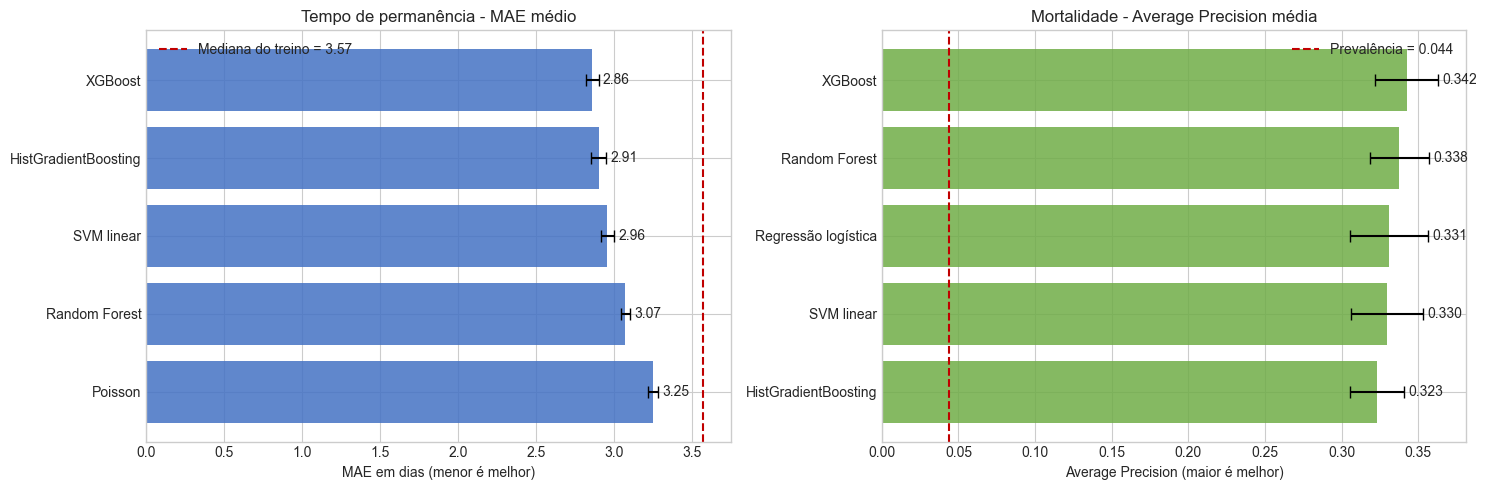

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

reg_plot = resumo_reg.drop(index="mediana_treino", errors="ignore").sort_values("mae_media", ascending=False)
barras = axes[0].barh([NOMES_MODELOS[x] for x in reg_plot.index], reg_plot["mae_media"],
                      xerr=reg_plot["mae_desvio"], color="#4472C4", alpha=.85, capsize=4)
mae_base = resumo_reg.loc["mediana_treino", "mae_media"]
axes[0].axvline(mae_base, color="#C00000", linestyle="--", label=f"Mediana do treino = {mae_base:.2f}")
axes[0].bar_label(barras, fmt="%.2f", padding=3)
axes[0].set_title("Tempo de permanência - MAE médio")
axes[0].set_xlabel("MAE em dias (menor é melhor)")
axes[0].legend()

clf_plot = resumo_clf.drop(index="prevalencia_treino", errors="ignore").sort_values("ap_media")
barras = axes[1].barh([NOMES_MODELOS[x] for x in clf_plot.index], clf_plot["ap_media"],
                      xerr=clf_plot["ap_desvio"], color="#70AD47", alpha=.85, capsize=4)
ap_base = resumo_clf.loc["prevalencia_treino", "ap_media"]
axes[1].axvline(ap_base, color="#C00000", linestyle="--", label=f"Prevalência = {ap_base:.3f}")
axes[1].bar_label(barras, fmt="%.3f", padding=3)
axes[1].set_title("Mortalidade - Average Precision média")
axes[1].set_xlabel("Average Precision (maior é melhor)")
axes[1].legend()

plt.tight_layout()
plt.show()

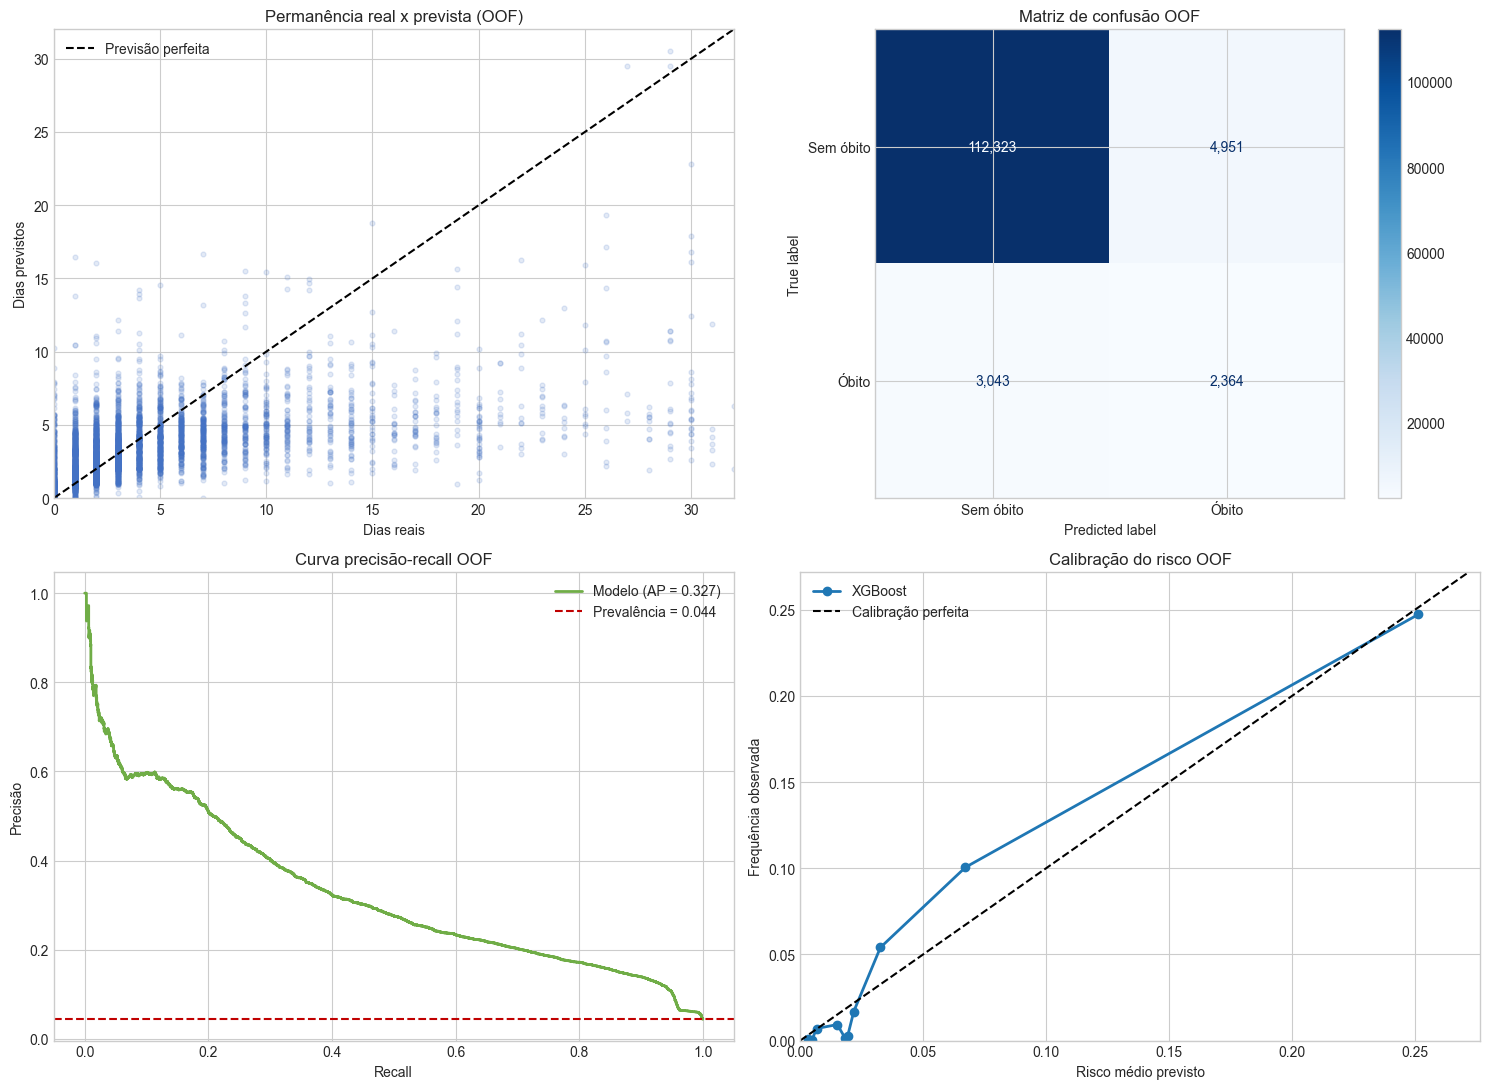

In [ ]:
oof_reg_melhor = previsoes_oof_reg.loc[previsoes_oof_reg["modelo"].eq(melhor_reg)].copy()
oof_clf_melhor = previsoes_oof_clf.loc[previsoes_oof_clf["modelo"].eq(melhor_clf)].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

amostra_plot = oof_reg_melhor.sample(min(5_000, len(oof_reg_melhor)), random_state=42)
limite = max(amostra_plot["real"].quantile(.99), amostra_plot["previsto"].quantile(.99))
axes[0, 0].scatter(amostra_plot["real"], amostra_plot["previsto"], alpha=.15, s=12, color="#4472C4")
axes[0, 0].plot([0, limite], [0, limite], "--", color="black", label="Previsão perfeita")
axes[0, 0].set_xlim(0, limite); axes[0, 0].set_ylim(0, limite)
axes[0, 0].set_title("Permanência real x prevista (OOF)")
axes[0, 0].set_xlabel("Dias reais"); axes[0, 0].set_ylabel("Dias previstos"); axes[0, 0].legend()

ConfusionMatrixDisplay.from_predictions(
    oof_clf_melhor["real"], oof_clf_melhor["previsto"],
    display_labels=["Sem óbito", "Óbito"], cmap="Blues", values_format=",d", ax=axes[0, 1]
)
axes[0, 1].set_title("Matriz de confusão OOF")

precisao, recall, _ = precision_recall_curve(oof_clf_melhor["real"], oof_clf_melhor["score"])
ap_oof = average_precision_score(oof_clf_melhor["real"], oof_clf_melhor["score"])
prevalencia = oof_clf_melhor["real"].mean()
axes[1, 0].plot(recall, precisao, color="#70AD47", linewidth=2, label=f"Modelo (AP = {ap_oof:.3f})")
axes[1, 0].axhline(prevalencia, color="#C00000", linestyle="--", label=f"Prevalência = {prevalencia:.3f}")
axes[1, 0].set_title("Curva precisão-recall OOF")
axes[1, 0].set_xlabel("Recall"); axes[1, 0].set_ylabel("Precisão"); axes[1, 0].legend()

frac_positivos, media_prevista = calibration_curve(
    oof_clf_melhor["real"], oof_clf_melhor["score"], n_bins=10, strategy="quantile"
)
axes[1, 1].plot(media_prevista, frac_positivos, marker="o", linewidth=2, label=NOMES_MODELOS[melhor_clf])
axes[1, 1].plot([0, 1], [0, 1], "--", color="black", label="Calibração perfeita")
axes[1, 1].set_title("Calibração do risco OOF")
axes[1, 1].set_xlabel("Risco médio previsto"); axes[1, 1].set_ylabel("Frequência observada")
axes[1, 1].set_xlim(0, max(.25, media_prevista.max() * 1.1))
axes[1, 1].set_ylim(0, max(.25, frac_positivos.max() * 1.1)); axes[1, 1].legend()

plt.tight_layout(); plt.show()

## 15. Resultados por mês, faixa de permanência e maturidade

Além das métricas mensais, essa seção avalia a regressão em três faixas: até 7 dias, de 8 a 30 dias e mais de 30 dias. Também compara o total mensal de diárias, relevante para planejamento de leitos.

A análise de sensibilidade compara os folds até setembro de 2025 com outubro-dezembro. Uma queda forte nos últimos meses pode indicar censura de internações longas ainda não encerradas nos arquivos disponíveis.


Regressão por mês - XGBoost


,mae,rmse,erro_mediano,r2,diarias_reais,diarias_previstas,erro_total_diarias_pct
mes,,,,,,,
2025-03-01,2.8182,6.0374,1.1324,0.1803,"55,385.0000","39,131.2671",0.2935
2025-04-01,2.9197,6.7525,1.0576,0.1510,"60,228.0000","40,782.5589",0.3229
2025-05-01,2.7916,6.1313,1.1511,0.1757,"60,063.0000","42,803.1366",0.2874
2025-06-01,2.8741,6.1709,1.1497,0.1891,"59,205.0000","41,382.7676",0.3010
2025-07-01,2.9016,6.0776,1.1720,0.1878,"59,485.0000","41,208.4447",0.3072
2025-08-01,2.8841,6.2369,1.1318,0.1713,"58,598.0000","40,620.0150",0.3068
2025-09-01,2.8926,6.3189,1.1240,0.1698,"59,615.0000","41,088.1848",0.3108
2025-10-01,2.8637,6.0888,1.1247,0.1873,"59,303.0000","41,392.6412",0.3020
2025-11-01,2.8469,6.0142,1.1169,0.2015,"56,535.0000","38,976.6891",0.3106


Regressão por faixa de permanência


,linhas,mae,rmse,erro_mediano,r2
faixa,,,,,
0-7 dias,101550,1.2906,1.8700,0.9399,-0.0093
8-30 dias,19639,8.5018,10.3017,6.8101,-1.8406
>30 dias,1492,35.5350,38.9326,30.7475,-5.5938


Sensibilidade à maturidade dos últimos meses


,mae,rmse,erro_mediano,r2
periodo,,,,
até setembro/2025,2.8688,6.2517,1.1301,0.1744
outubro-dezembro/2025,2.8436,6.0379,1.1192,0.1943


Classificação por mês - XGBoost


,prevalencia,limiar,taxa_alertas,average_precision,roc_auc,brier,precision,recall,f1,balanced_accuracy
mes,,,,,,,,,,
2025-03-01,0.0417,0.2220,0.0527,0.3343,0.9049,0.0328,0.3510,0.4433,0.3918,0.7038
2025-04-01,0.0424,0.1031,0.0492,0.3185,0.8937,0.0355,0.3274,0.3800,0.3517,0.6727
2025-05-01,0.0466,0.2130,0.0624,0.3451,0.8979,0.0363,0.3288,0.4402,0.3764,0.6981
2025-06-01,0.0470,0.2092,0.0661,0.3327,0.8983,0.0367,0.3268,0.4596,0.3820,0.7064
2025-07-01,0.0465,0.1238,0.0563,0.3461,0.8940,0.0374,0.3238,0.3921,0.3547,0.6761
2025-08-01,0.0454,0.1030,0.0678,0.3551,0.9041,0.0371,0.3189,0.4767,0.3822,0.7142
2025-09-01,0.0423,0.2194,0.0594,0.3091,0.9029,0.0341,0.2903,0.4075,0.3391,0.6818
2025-10-01,0.0427,0.0915,0.0672,0.3455,0.9004,0.0350,0.2989,0.4701,0.3655,0.7105
2025-11-01,0.0419,0.1761,0.0695,0.3829,0.9083,0.0319,0.3188,0.5281,0.3976,0.7394


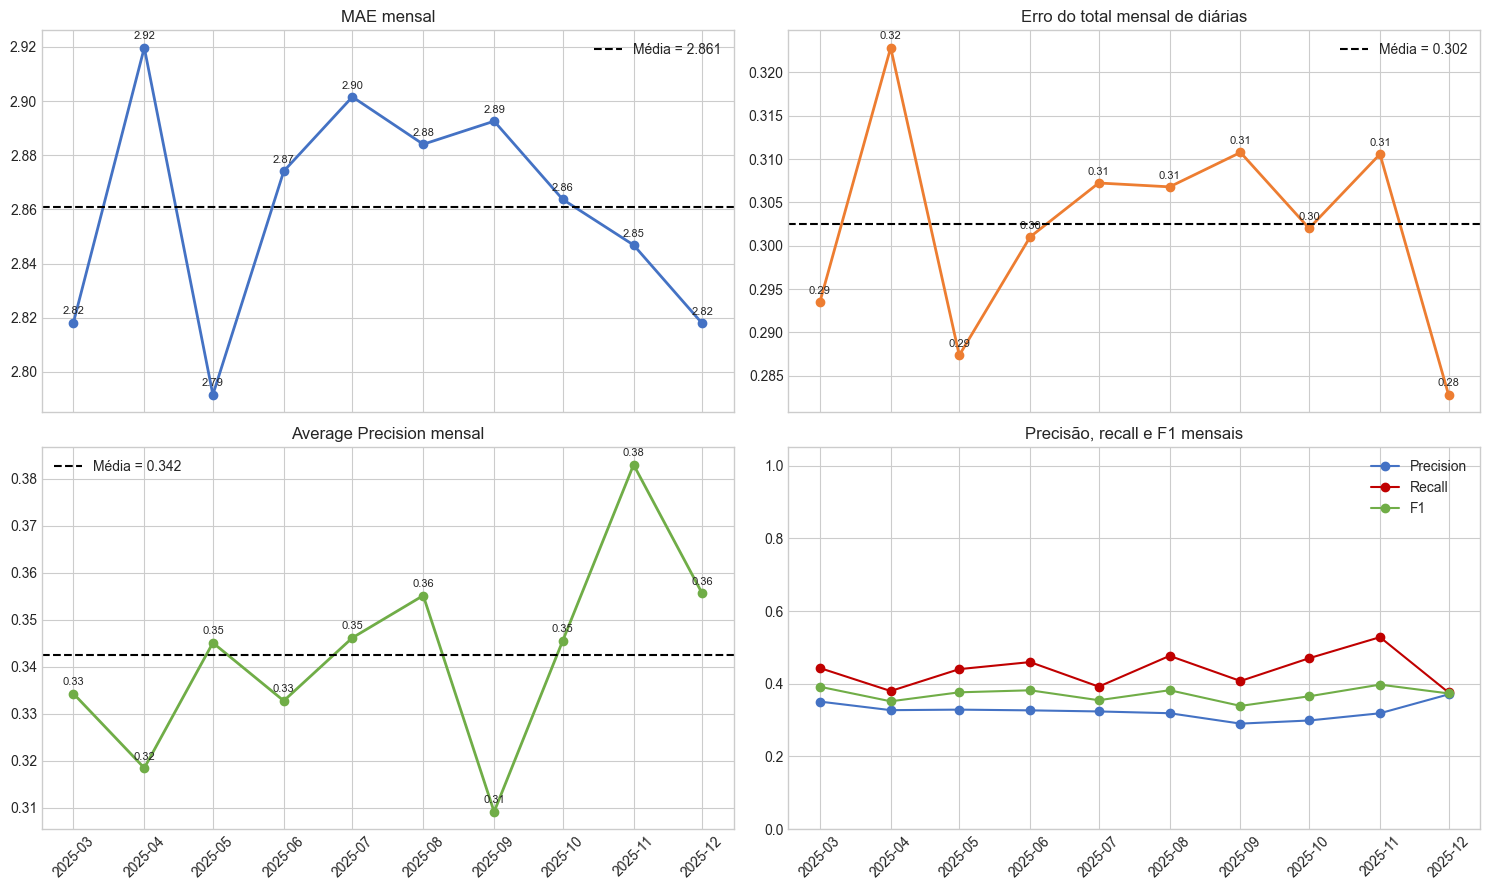

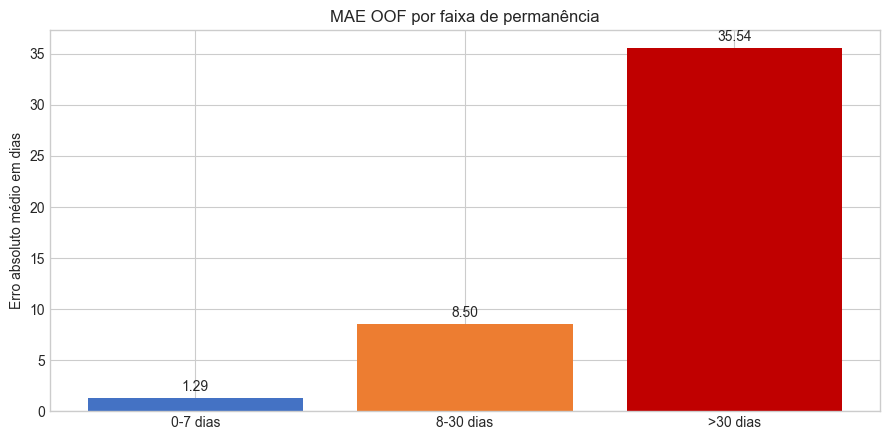

In [ ]:
reg_mensal = []
for mes, grupo in oof_reg_melhor.groupby("mes"):
    total_real = grupo["real"].sum()
    total_previsto = grupo["previsto"].sum()
    reg_mensal.append({
        "mes": mes, **metricas_regressao(grupo["real"], grupo["previsto"]),
        "diarias_reais": total_real, "diarias_previstas": total_previsto,
        "erro_total_diarias_pct": abs(total_previsto - total_real) / total_real,
    })
reg_mensal = pd.DataFrame(reg_mensal).set_index("mes")

clf_mensal = []
for mes, grupo in oof_clf_melhor.groupby("mes"):
    clf_mensal.append({
        "mes": mes, "prevalencia": grupo["real"].mean(),
        "limiar": grupo["limiar"].mean(), "taxa_alertas": grupo["previsto"].mean(),
        **metricas_classificacao(grupo["real"], grupo["score"], grupo["previsto"]),
    })
clf_mensal = pd.DataFrame(clf_mensal).set_index("mes")

oof_reg_melhor["faixa_permanencia"] = pd.cut(
    oof_reg_melhor["real"], bins=[-0.1, 7, 30, np.inf],
    labels=["0-7 dias", "8-30 dias", ">30 dias"],
)
linhas_faixa = []
for faixa, grupo in oof_reg_melhor.groupby("faixa_permanencia", observed=True):
    linhas_faixa.append({"faixa": faixa, "linhas": len(grupo),
                         **metricas_regressao(grupo["real"], grupo["previsto"])})
reg_por_faixa = pd.DataFrame(linhas_faixa).set_index("faixa")

sensibilidade_maturidade = pd.DataFrame([
    {"periodo": "até setembro/2025", **metricas_regressao(
        oof_reg_melhor.loc[oof_reg_melhor["mes"].le(pd.Timestamp("2025-09-01")), "real"],
        oof_reg_melhor.loc[oof_reg_melhor["mes"].le(pd.Timestamp("2025-09-01")), "previsto"],
    )},
    {"periodo": "outubro-dezembro/2025", **metricas_regressao(
        oof_reg_melhor.loc[oof_reg_melhor["mes"].gt(pd.Timestamp("2025-09-01")), "real"],
        oof_reg_melhor.loc[oof_reg_melhor["mes"].gt(pd.Timestamp("2025-09-01")), "previsto"],
    )},
]).set_index("periodo")

print("Regressão por mês -", NOMES_MODELOS[melhor_reg]); display(reg_mensal)
print("Regressão por faixa de permanência"); display(reg_por_faixa)
print("Sensibilidade à maturidade dos últimos meses"); display(sensibilidade_maturidade)
print("Classificação por mês -", NOMES_MODELOS[melhor_clf]); display(clf_mensal)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
graficos = [
    (axes[0, 0], reg_mensal, "mae", "MAE mensal", "#4472C4"),
    (axes[0, 1], reg_mensal, "erro_total_diarias_pct", "Erro do total mensal de diárias", "#ED7D31"),
    (axes[1, 0], clf_mensal, "average_precision", "Average Precision mensal", "#70AD47"),
]
for ax, tabela, coluna, titulo, cor in graficos:
    ax.plot(tabela.index, tabela[coluna], marker="o", linewidth=2, color=cor)
    media = tabela[coluna].mean()
    ax.axhline(media, color="black", linestyle="--", label=f"Média = {media:.3f}")
    for x, y in zip(tabela.index, tabela[coluna]):
        ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
    ax.set_title(titulo); ax.legend()

for coluna, cor in [("precision", "#4472C4"), ("recall", "#C00000"), ("f1", "#70AD47")]:
    axes[1, 1].plot(clf_mensal.index, clf_mensal[coluna], marker="o", label=coluna.capitalize(), color=cor)
axes[1, 1].set_title("Precisão, recall e F1 mensais"); axes[1, 1].set_ylim(0, 1.05); axes[1, 1].legend()
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(reg_por_faixa.index.astype(str), reg_por_faixa["mae"], color=["#4472C4", "#ED7D31", "#C00000"])
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_title("MAE OOF por faixa de permanência"); ax.set_ylabel("Erro absoluto médio em dias")
plt.tight_layout(); plt.show()

## 16. Exportação para a comparação clássica-quântica

São salvos cinco arquivos essenciais: base congelada, protocolo, métricas por fold, resumo e guia. O CSV por fold agora inclui hiperparâmetros, peso positivo, limiar, taxa de alertas e matriz de confusão.


In [ ]:
def sha256(caminho):
    resumo = hashlib.sha256()
    with open(caminho, "rb") as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
            resumo.update(bloco)
    return resumo.hexdigest()


if EXPORTAR_PROTOCOLO:
    DIR_SAIDA.mkdir(parents=True, exist_ok=True)

    base_congelada = base_modelagem[[
        "id_linha", "data_internacao", "mes", *FEATURES, ALVO_REG, ALVO_CLF
    ]].copy()
    base_congelada["fold_teste"] = pd.Series(pd.NA, index=base_congelada.index, dtype="Int64")

    folds_json = []
    for fold, (idx_tr, idx_te) in enumerate(folds_externos, 1):
        indices_teste = base_modelagem.iloc[idx_te].index
        base_congelada.loc[indices_teste, "fold_teste"] = fold
        treino = base_modelagem.iloc[idx_tr]
        teste = base_modelagem.iloc[idx_te]
        folds_json.append({
            "fold": fold, "treino_inicio": str(treino["mes"].min().date()),
            "treino_fim": str(treino["mes"].max().date()),
            "teste_mes": str(teste["mes"].iloc[0].date()),
        })

    caminho_base = DIR_SAIDA / "base_modelagem_congelada.parquet"
    base_congelada.to_parquet(caminho_base, index=False, compression="zstd")

    protocolo = {
        "versao": 2, "tipo_avaliacao": "nested_rolling_origin_sem_holdout",
        "unidade": "AIH (evento de internacao)",
        "periodo": [str(DATA_INICIAL.date()), str(DATA_FINAL.date())],
        "fracao_amostra": FRACAO_AMOSTRA, "seed_amostra": SEED_AMOSTRA,
        "features": FEATURES,
        "alvo_regressao": ALVO_REG, "alvo_classificacao": ALVO_CLF,
        "metrica_principal_regressao": "MAE",
        "metrica_principal_classificacao": "Average Precision",
        "calibracao_classificacao": "Platt na validacao interna",
        "criterio_limiar": "maior F1 na validacao interna",
        "pesos_positivos_testados": PESOS_POSITIVOS,
        "meses_validacao_interna": MESES_VALIDACAO_INTERNA,
        "seed_modelos": SEED_TUNING, "folds": folds_json,
        "grades_regressao": GRADES_REGRESSAO,
        "grades_classificacao": GRADES_CLASSIFICACAO,
    }
    with open(DIR_SAIDA / "protocolo.json", "w", encoding="utf-8") as arquivo:
        json.dump(protocolo, arquivo, ensure_ascii=False, indent=2)

    parametros_reg = selecoes_reg[["fold", "modelo", "parametros"]]
    parametros_clf = selecoes_clf[["fold", "modelo", "parametros"]]
    resultados_reg_export = metricas_reg_fold.merge(parametros_reg, on=["fold", "modelo"], how="left").assign(tarefa="regressao")
    resultados_clf_export = metricas_clf_fold.merge(parametros_clf, on=["fold", "modelo"], how="left").assign(tarefa="classificacao")
    pd.concat([resultados_reg_export, resultados_clf_export], ignore_index=True, sort=False).to_csv(
        DIR_SAIDA / "resultados_classicos_por_fold.csv", index=False
    )
    pd.concat([
        resumo_reg.reset_index().assign(tarefa="regressao"),
        resumo_clf.reset_index().assign(tarefa="classificacao"),
    ], ignore_index=True, sort=False).to_csv(DIR_SAIDA / "resumo_classicos.csv", index=False)

    codigo_sha = sha256(caminho_base)
    guia = f'''COMPARAÇÃO CLÁSSICA-QUÂNTICA - SIH-SUS

  ARQUIVOS DESTA PASTA
  1. base_modelagem_congelada.parquet: features, alvos e fold de teste.
  2. protocolo.json: nomes das features, alvos, datas, métricas e seed.
  3. resultados_classicos_por_fold.csv: métricas e parâmetros de cada fold.
  4. resumo_classicos.csv: média e desvio dos modelos clássicos.
  5. LEIA_ME_COMPARACAO.txt: este guia.

  NÃO É NECESSÁRIO BAIXAR OS PARQUETS BRUTOS DO SIA-SUS.
  A base congelada já contém tudo que entra nos modelos. Os arquivos brutos só
  seriam necessários para auditar ou refazer o ETL desde o início.

  BASE
  - unidade: uma AIH;
  - classificação: morte;
  - regressão: dias_permanencia;

  COMO USAR OS FOLDS
  - teste: fold_teste igual ao número do fold;
  - treino externo: meses anteriores ao teste;
  - validação interna: últimos 2 meses do treino externo;
  - linhas sem fold_teste pertencem somente ao histórico de treino;
  - hiperparâmetros, peso positivo, calibração e limiar não consultam o teste;
  - todos os modelos usam a seed fixa 42;
  - reportar média, desvio e tempo entre os mesmos folds.
'''
    (DIR_SAIDA / "LEIA_ME_COMPARACAO.txt").write_text(guia, encoding="utf-8")

    print("Arquivos exportados em:", DIR_SAIDA.resolve())
    print("SHA-256 da base:", codigo_sha)
else:
    print("Exportação desativada.")

Arquivos exportados em: C:\Users\laris\Documents\QIMED\dataset-datasus\qimed_mlops\SIH-SUS\resultados_mortalidade_permanencia
SHA-256 da base: 395b5b355d4c227074e598f4224b0fb6cbb13ec55a4184ff2f2bae5f6ab0436b
